# 64채널·Conv1D 3층 하이퍼파라미터 튜닝

실행 전 노트북입니다. GELU, residual 연결, max pooling과 MERT 입력은 유지합니다.
입력 투영 Conv1D(768→64, kernel 1) 뒤에 시간축 Conv1D(kernel 3) 3층을 둡니다.
학습률·weight decay·dropout·batch size·crop·특징 마스킹·NSynth 가중치를 탐색합니다.
24개 설정을 seed 41로 비교하고 상위 4개를 seed 42·43에서도 학습합니다.
튜닝 Music EER 3개 seed 평균→표준편차→BCE 순으로 최종 후보를 선택합니다.
최대 300 epoch, patience 20이며 최저 튜닝 BCE 가중치를 복원합니다.

선택을 고정한 뒤 기존 128채널·2층, 튜닝 전 64채널·3층, 선택한 64채널·3층을 비교합니다.
기존 공개 평가 자료를 재사용합니다. 전체 공식 점수는 정답 누락으로 계산할 수 없습니다.
파일·음악 가중 부분합은 공식 총점이 아니며, 평가 결과로 설정이나 seed를 다시 고르지 않습니다.


## 1. 환경과 입력 확인

In [1]:
from pathlib import Path
import json, os, sys, time
import numpy as np
import torch
from IPython.display import display, Markdown
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
from v6_data import sha256, write_json
from temporal_experiment import split_experiment, load_features, training_masks, evaluate_locked_test
from temporal_tuning import run_compact_search
BATCH_SIZE = 128
OUT = ROOT / 'results'; OUT.mkdir(exist_ok=True)
PROJECT = Path('/root/V6_L40S'); FINAL = Path('/root/C3_Final')
DEADLINE = float(os.environ['V7_RESUMED_EPOCH']) + 30 * 60
manifest = json.loads((ROOT / 'input_manifest.json').read_text())
for name, digest in manifest['sha256'].items():
    assert sha256(ROOT / name) == digest, name
assert torch.cuda.is_available() and time.time() < DEADLINE
torch.set_num_threads(4)
torch.backends.cudnn.benchmark = False
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
torch.use_deterministic_algorithms(True)
write_json(OUT / 'environment.json', dict(gpu=torch.cuda.get_device_name(), torch=torch.__version__,
    python=sys.version, deadline=DEADLINE, batch_size=BATCH_SIZE, deterministic_algorithms=True))
print({'GPU': torch.cuda.get_device_name(), 'torch': torch.__version__, 'compute_minutes': 30})

{'GPU': 'NVIDIA H100 80GB HBM3', 'torch': '2.9.1+cu130', 'compute_minutes': 30}


## 2. 분할과 캐시 검증
기존 C3 정제 정책을 유지합니다. PCM 중복과 유효 구간 없는 자료를 제외하고, 학습 자료에만 활성 프레임 비율 20% 기준 마스크를 적용합니다. 평가 자료에는 학습용 마스크를 적용하지 않습니다.

In [2]:
PLAN = json.loads((ROOT / 'full_data_plan.json').read_text())
BASELINE = json.loads((ROOT / 'baseline_predictions.json').read_text())
SPLIT = json.loads((ROOT / 'locked_split.json').read_text())
from v6_data import assert_disjoint
for a,b in [('train','tune'),('train','test'),('tune','test')]:
    assert_disjoint(SPLIT[a], SPLIT[b])
write_json(OUT / 'split.json', SPLIT)
records = load_features(SPLIT['train'] + SPLIT['tune'] + SPLIT['test'], PROJECT, FINAL)
masked = training_masks(SPLIT['train'], records, PLAN['quality'])
write_json(OUT / 'input_verification.json', dict(files=len(records), input_sha256=manifest['sha256'],
    split_sha256=sha256(OUT / 'split.json'), quality_policy=PLAN['policy'],
    baseline_sha256=sha256(ROOT / 'baseline_predictions.json'),
    cache_validation='Source audio SHA256 checked by CPU exporter; exact cache SHA256 and original identity checked on H100'))
from collections import Counter
for name, rows in SPLIT.items():
    print(name, len(rows), dict(Counter(r['source'].split('/')[0] for r in rows)))
import hashlib
def feature_hash(mapping):
    digest=hashlib.sha256()
    for key in sorted(mapping):
        digest.update(key.encode())
        for field in ('music','music_audible','starts'):
            digest.update(np.ascontiguousarray(mapping[key][field]).tobytes())
    return digest.hexdigest()
CACHE_BEFORE=(feature_hash(records),feature_hash(masked))


train 1008 {'Echoes': 857, 'nsynth': 90, 'FMA': 61}
tune 248 {'FMA': 19, 'Echoes': 129, 'mixture': 80, 'splice': 20}
test 190 {'splice': 20, 'mixture': 80, 'Echoes': 40, 'MLAAD': 40, 'FMA': 10}


## 3. 튜닝 데이터로 후보 선택
탐색 설정과 shortlist를 저장한 뒤 seed 반복을 진행합니다.
원본 캐시 불변성과 기존 128채널 모델의 학습 곡선 재현을 확인합니다.

In [3]:
search = run_compact_search(
    SPLIT['train'], SPLIT['tune'], records, masked, OUT, DEADLINE)
assert CACHE_BEFORE == (feature_hash(records), feature_hash(masked)), 'Feature cache mutated'
write_json(OUT/'cache_integrity.json', dict(unchanged=True, original_sha256=CACHE_BEFORE))
reference = json.loads((ROOT/'reference_simple.json').read_text())
for seed in (41,42,43):
    current = json.loads((OUT/f'S128_seed{seed}'/'training.json').read_text())
    previous = reference[str(seed)]
    for field in ('train_losses', 'validation_losses'):
        np.testing.assert_allclose(current[field], previous[field], atol=1e-6, rtol=0)
    assert current['selected_epoch'] == previous['selected_epoch']
write_json(OUT/'prior_reproduction.json', dict(passed=True, tolerance=1e-6, seeds=[41,42,43]))
selection = json.loads((OUT/'selection.json').read_text())
lines = ['| 설정 | 3-seed 튜닝 EER | 표준편차 | BCE |', '|---|---:|---:|---:|']
for r in selection['summaries']:
    lines.append(f"| {r['name']} | {r['music_eer_mean']:.4f} | {r['music_eer_std']:.4f} | {r['balanced_bce_mean']:.4f} |")
display(Markdown('\n'.join(lines)))
print('Selected using tune only:', selection['winner']['name'], selection['winner']['recipe'])


C00_seed41 {'music_eer': 0.31863816695004454, 'balanced_bce': 0.5778319153968904} epoch 6


C01_seed41 {'music_eer': 0.3030119018702939, 'balanced_bce': 0.5708488314248055} epoch 12


C02_seed41 {'music_eer': 0.39118290017002677, 'balanced_bce': 0.6596942443709752} epoch 3


C03_seed41 {'music_eer': 0.3627236660999109, 'balanced_bce': 0.5882360562247093} epoch 12


C04_seed41 {'music_eer': 0.30580519795967936, 'balanced_bce': 0.5794343545811934} epoch 88


...

S128_seed41 {'music_eer': 0.2901789328799288, 'balanced_bce': 0.5764365420199037} epoch 3


S128_seed42 {'music_eer': 0.31863816695004454, 'balanced_bce': 0.5701571583453433} epoch 6


S128_seed43 {'music_eer': 0.2929722289693142, 'balanced_bce': 0.5606693848084127} epoch 9


| 설정 | 3-seed 튜닝 EER | 표준편차 | BCE |
|---|---:|---:|---:|
| C00 | 0.3134 | 0.0298 | 0.5779 |
| C08 | 0.2755 | 0.0106 | 0.5568 |
| C05 | 0.2997 | 0.0248 | 0.5860 |
| C21 | 0.2764 | 0.0215 | 0.5505 |
| C19 | 0.2859 | 0.0278 | 0.5668 |
| S128 | 0.3006 | 0.0128 | 0.5691 |

Selected using tune only: C08 {'epochs': 300, 'patience': 20, 'min_delta': 0.0001, 'batch_size': 64, 'learning_rate': 0.0001, 'weight_decay': 0.0, 'nsynth_mass': 0.0, 'seed': 41, 'dropout': 0.0, 'crop_probability': 0.7, 'feature_mask_probability': 0.3, 'simplified': True, 'compact': True}


## 4. 고정한 후보와 대조군 평가
평가 190개 중 음악 EER 대상은 150개입니다. 음성·존재 확률과 파일 max 결합식을 유지합니다.
가중 부분합은 0.45×(1−File EER)+0.27×(1−Music EER)이며 전체 공식 점수가 아닙니다.

In [4]:
reports = evaluate_locked_test(SPLIT['test'], records, BASELINE, OUT)
assert CACHE_BEFORE == (feature_hash(records), feature_hash(masked))
for r in reports:
    r['file_eer'] = r['metrics']['metrics']['file_eer']
    r['file_music_partial'] = .45*(1-r['file_eer']) + .27*(1-r['music_eer'])
test_summaries = []
for s in selection['summaries']:
    if s['name'] not in selection['comparison_groups']:
        continue
    matched = [r for r in reports if r['name'] in s['candidates']]
    summary = dict(name=s['name'])
    for metric in ('music_eer','file_eer','file_music_partial','balanced_bce'):
        values = [r[metric] for r in matched]
        summary[metric+'_mean'] = float(np.mean(values))
        summary[metric+'_std'] = float(np.std(values))
    test_summaries.append(summary)
write_json(OUT/'comparison_summary.json', dict(tune=selection['summaries'],
    historical_test=test_summaries, per_seed=reports,
    partial_score_definition='.45*(1-file_eer)+.27*(1-music_eer); not full official score',
    no_seed_selected_using_test=True))
lines = ['| 모델 | Music EER ↓ | File EER ↓ | 파일·음악 가중 부분합 ↑ |',
         '|---|---:|---:|---:|']
for r in reports:
    lines.append(f"| {r['name']} | {r['music_eer']:.4f} | {r['file_eer']:.4f} | {r['file_music_partial']:.4f} |")
display(Markdown('\n'.join(lines)))
lines = ['| 구조 | 평균 Music EER | 평균 File EER | 평균 가중 부분합 |', '|---|---:|---:|---:|']
for r in test_summaries:
    lines.append(f"| {r['name']} | {r['music_eer_mean']:.4f} | {r['file_eer_mean']:.4f} | {r['file_music_partial_mean']:.4f} |")
display(Markdown('\n'.join(lines)))


| 모델 | Music EER ↓ | File EER ↓ | 파일·음악 가중 부분합 ↑ |
|---|---:|---:|---:|
| Official_baseline | 0.5528 | 0.4321 | 0.3763 |
| Linear_same_split | 0.3667 | 0.3519 | 0.4626 |
| C00_seed41 | 0.3333 | 0.3160 | 0.4878 |
| C00_seed42 | 0.2472 | 0.3000 | 0.5182 |
| C00_seed43 | 0.2861 | 0.3160 | 0.5005 |
| C08_seed41 | 0.3139 | 0.3160 | 0.4930 |
| C08_seed42 | 0.2528 | 0.3160 | 0.5095 |
| C08_seed43 | 0.3194 | 0.3321 | 0.4843 |
| S128_seed41 | 0.4194 | 0.3519 | 0.4484 |
| S128_seed42 | 0.3528 | 0.3000 | 0.4898 |
| S128_seed43 | 0.3472 | 0.3160 | 0.4840 |

| 구조 | 평균 Music EER | 평균 File EER | 평균 가중 부분합 |
|---|---:|---:|---:|
| C00 | 0.2889 | 0.3107 | 0.5022 |
| C08 | 0.2954 | 0.3214 | 0.4956 |
| S128 | 0.3731 | 0.3226 | 0.4741 |

## 5. 평가 결과와 학습 곡선
오차 막대는 seed 3개의 모집단 표준편차이며 신뢰구간이 아닙니다.
튜닝 전후를 구분하고 모든 seed의 튜닝 BCE를 표시합니다.

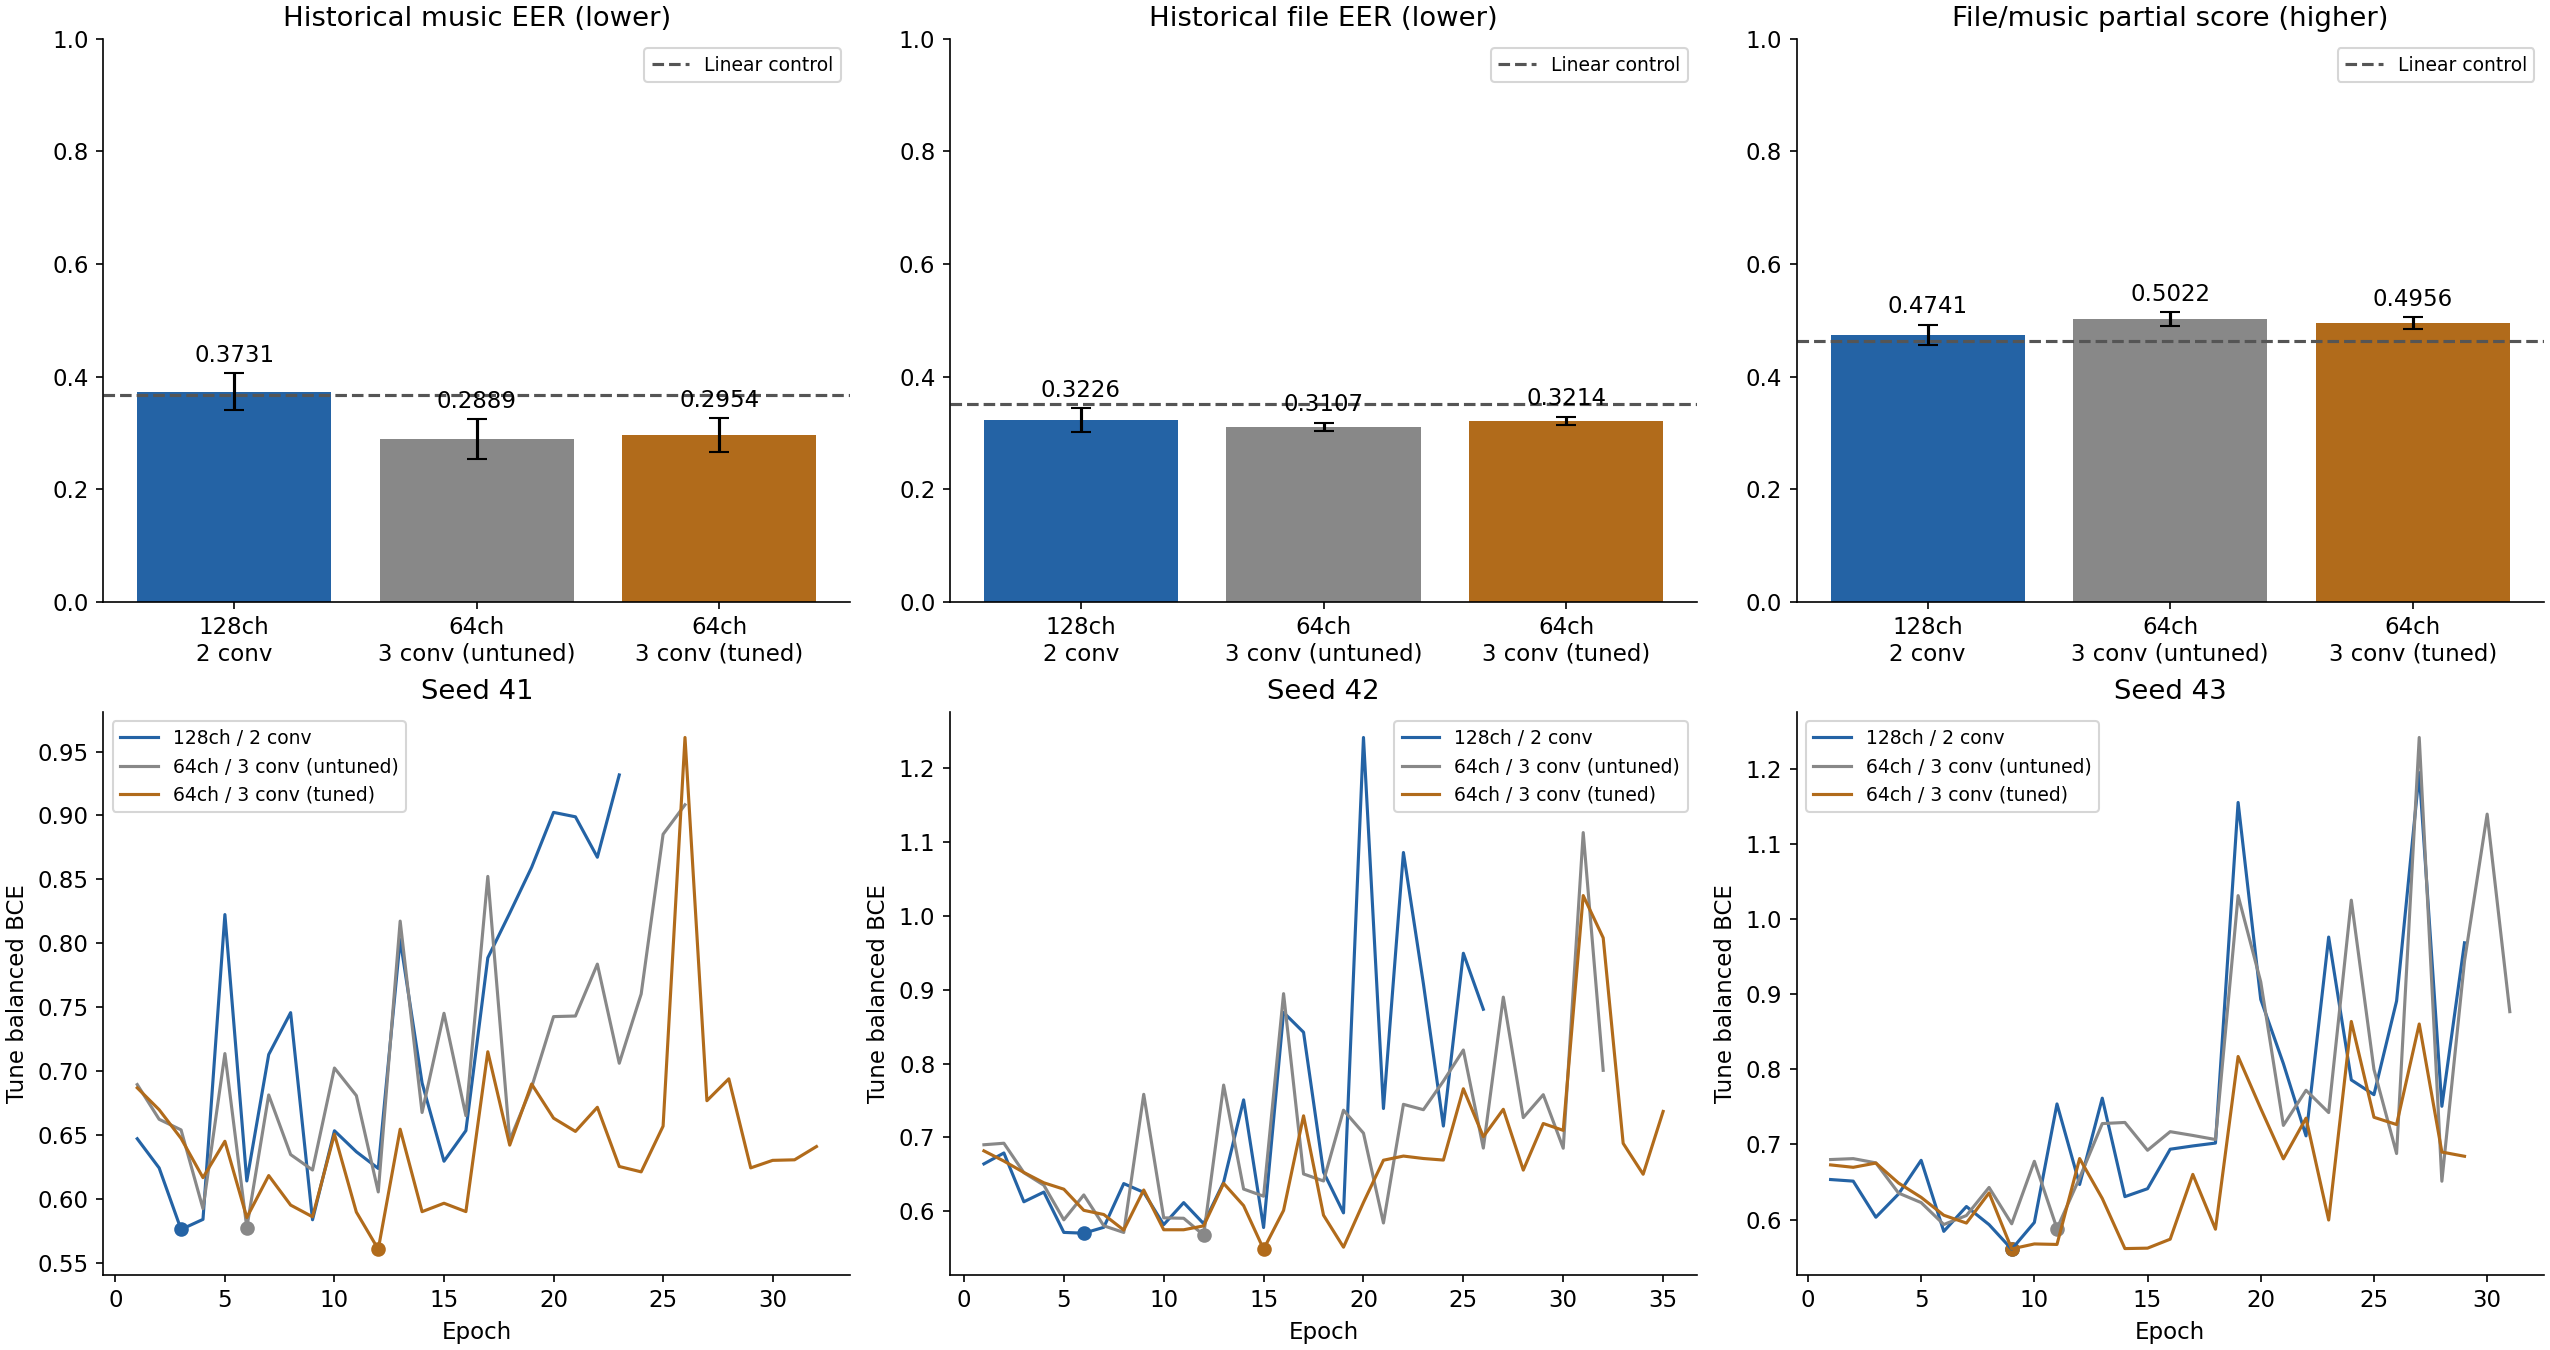

모든 탐색 가중치·곡선·튜닝 예측을 저장했습니다. 평가 결과로 후보를 다시 선택하지 않았습니다.

In [5]:
import matplotlib.pyplot as plt
from IPython.display import Image
plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False})
winner = selection['winner']['name']
settings = list(dict.fromkeys(['S128','C00',winner]))
labels = {'S128':'128ch / 2 conv', 'C00':'64ch / 3 conv (untuned)'}
if winner != 'C00':
    labels[winner] = '64ch / 3 conv (tuned)'
colors = ['#2463a5','#888888','#b16b1b'][:len(settings)]
lookup = {r['name']:r for r in test_summaries}
fig, axes = plt.subplots(2,3,figsize=(17,9),layout='constrained')
for ax,metric,title in zip(axes[0],['music_eer','file_eer','file_music_partial'],
                         ['Historical music EER (lower)','Historical file EER (lower)','File/music partial score (higher)']):
    values = [lookup[s][metric+'_mean'] for s in settings]
    spread = [lookup[s][metric+'_std'] for s in settings]
    ax.bar(range(len(settings)), values, yerr=spread, capsize=5, color=colors)
    ax.set(xticks=range(len(settings)),xticklabels=[labels[s].replace(' / ','\n') for s in settings],
           title=title,ylim=(0,1))
    for i,value in enumerate(values):
        ax.text(i,value+spread[i]+.02,f'{value:.4f}',ha='center')
    ax.axhline(reports[1][metric],color='#555555',linestyle='--',label='Linear control')
    ax.legend(fontsize=9)
for ax,seed in zip(axes[1],(41,42,43)):
    for setting,color in zip(settings,colors):
        trace = json.loads((OUT/f'{setting}_seed{seed}'/'training.json').read_text())
        y = trace['validation_losses']
        ax.plot(np.arange(1,len(y)+1),y,color=color,label=labels[setting])
        ax.scatter([trace['selected_epoch']],[trace['best_validation_loss']],color=color)
    ax.set(xlabel='Epoch',ylabel='Tune balanced BCE',title=f'Seed {seed}')
    ax.legend(fontsize=9)
fig.savefig(OUT/'comparison.png',dpi=150)
plt.close(fig)
display(Image(filename=str(OUT/'comparison.png')))
display(Markdown('모든 탐색 가중치·곡선·튜닝 예측을 저장했습니다. 평가 결과로 후보를 다시 선택하지 않았습니다.'))
